# 01 · Calidad y exploración de los datos

Primer contacto con el CSV original (`data/raw/telco-customer-churn.csv`): estructura, calidad,
distribución de cada variable y su relación con el abandono (`Churn`).

Salidas: `ml/reports/figures/exploracion/*.png`

In [1]:
import sys

sys.path.insert(0, "..")  # para importar el paquete telco desde ml/notebooks

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from telco import paths, style
from telco.data import load_raw
from telco.style import CHURN, MUTED, RAW_LABELS, STAY, VALUE_LABELS

style.apply()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 1. Estructura y calidad
`TotalCharges` llega como texto. Se revisa si hay valores vacíos antes de convertirlo a número.

In [2]:
raw = load_raw(numeric_total=False)
print(f"Filas: {len(raw):,} · Columnas: {raw.shape[1]}")
blanks = raw.select_dtypes(exclude="number").apply(lambda s: (s.str.strip() == "").sum())
print("Textos vacíos:", blanks[blanks > 0].to_dict() or "ninguno")
raw.dtypes.to_frame("tipo").T

Filas: 7,043 · Columnas: 21
Textos vacíos: {'TotalCharges': 11}


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
tipo,str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,str,str


In [3]:
df = load_raw()
TARGET = "Churn"
cols = [c for c in df.columns if c not in ("customerID", TARGET)]
numeric = [c for c in cols if pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() > 2]
categorical = [c for c in cols if c not in numeric]

nulls = df[df["TotalCharges"].isna()]
print("Nulos tras convertir TotalCharges:", df.isna().sum()[lambda s: s > 0].to_dict())
print("  antigüedad de esas filas:", sorted(nulls["tenure"].unique().tolist()), "-> clientes nuevos, aún sin facturar")
print("Filas duplicadas:", df.duplicated().sum())
print("customerID duplicados:", df["customerID"].duplicated().sum())
print("Perfiles idénticos si se ignora el ID:", df.drop(columns="customerID").duplicated().sum(),
      "(clientes distintos con el mismo plan; se conservan)")

Nulos tras convertir TotalCharges: {'TotalCharges': 11}
  antigüedad de esas filas: [0] -> clientes nuevos, aún sin facturar
Filas duplicadas: 0
customerID duplicados: 0
Perfiles idénticos si se ignora el ID: 22 (clientes distintos con el mismo plan; se conservan)


## 2. Balance del objetivo
Un 26,5 % abandona: un modelo que diga siempre «no abandona» ya acierta el 73,5 %. Por eso la
exactitud no sirve para elegir modelo (ver notebook 05).

In [4]:
df[TARGET].value_counts().to_frame("clientes").assign(pct=lambda t: (t.clientes / len(df) * 100).round(2))

,clientes,pct
Churn,,
No,5174,73.46
Yes,1869,26.54


## 3. Distribuciones

In [5]:
df[numeric].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7032.0,2283.30,2266.77,18.80,401.45,1397.48,3794.74,8684.80


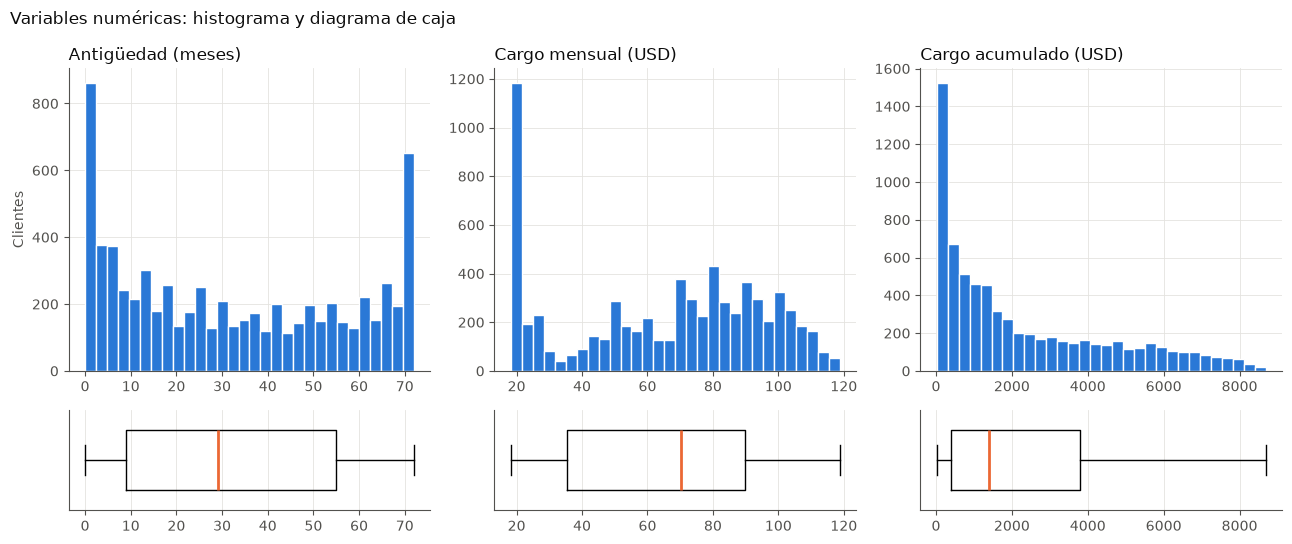

In [6]:
fig, axes = plt.subplots(2, len(numeric), figsize=(13, 5.5), gridspec_kw={"height_ratios": [3, 1]})
for j, c in enumerate(numeric):
    axes[0, j].hist(df[c].dropna(), bins=30, color=STAY, edgecolor="white")
    axes[0, j].set_title(RAW_LABELS[c], loc="left")
    axes[0, j].set_ylabel("Clientes" if j == 0 else "")
    axes[1, j].boxplot(df[c].dropna(), orientation="horizontal", widths=0.6,
                       medianprops={"color": CHURN, "linewidth": 2}, flierprops={"markersize": 3})
    axes[1, j].set_yticks([])
fig.suptitle("Variables numéricas: histograma y diagrama de caja", x=0.01, ha="left")
fig.tight_layout()
style.save(fig, paths.figure("exploracion", "dist_numericas.png"))

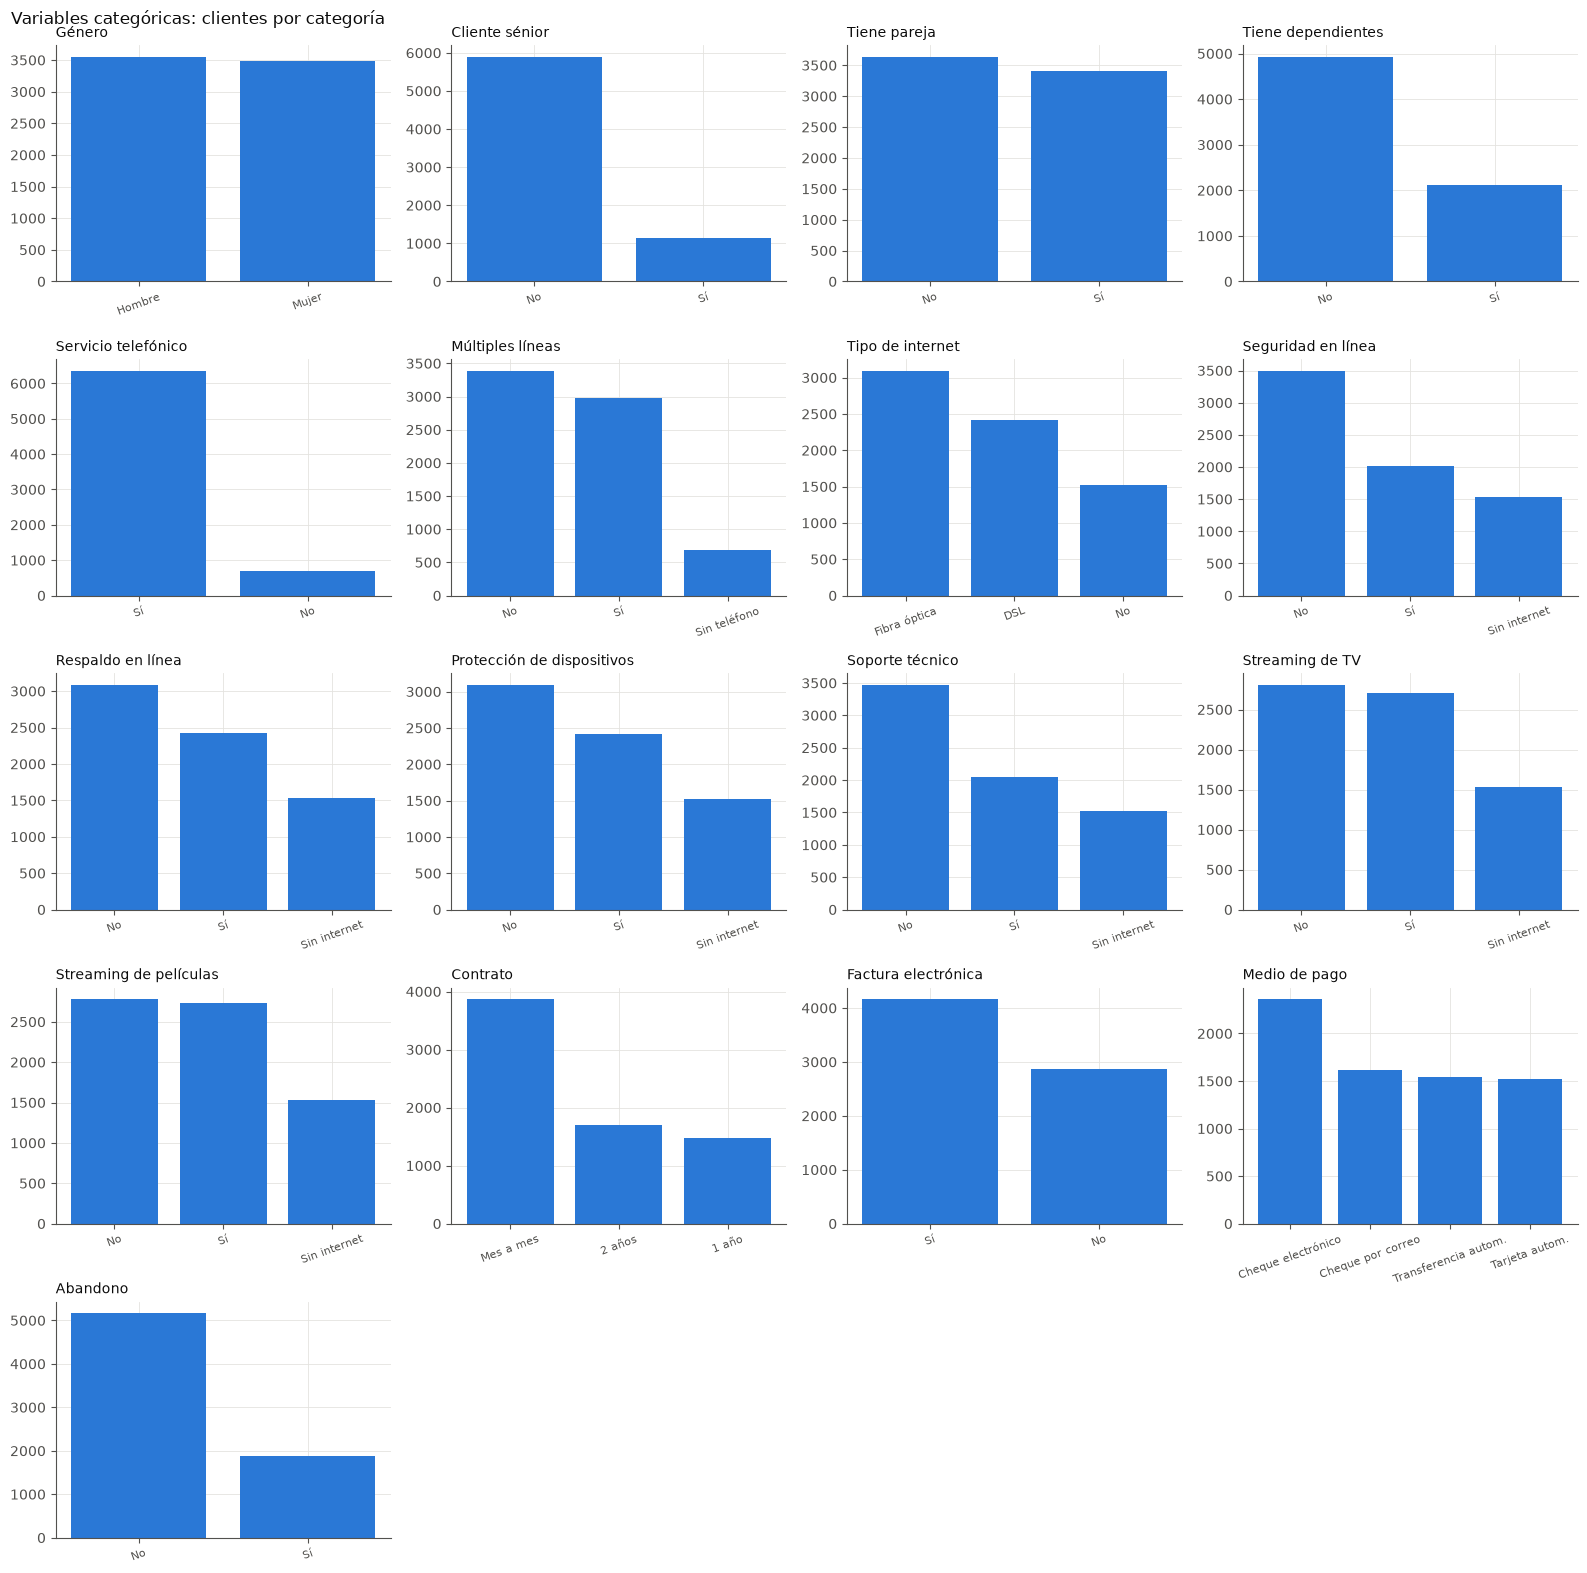

In [7]:
plot_cols = categorical + [TARGET]
rows = (len(plot_cols) + 3) // 4
fig, axes = plt.subplots(rows, 4, figsize=(16, 3.2 * rows))
for ax, c in zip(axes.flat, plot_cols):
    counts = df[c].value_counts()
    ax.bar(counts.index.astype(str).map(lambda v: VALUE_LABELS.get(v, v)), counts.values, color=STAY)
    ax.set_title(RAW_LABELS[c], loc="left", fontsize=10)
    ax.tick_params(axis="x", labelrotation=20, labelsize=8)
for ax in axes.flat[len(plot_cols):]:
    ax.remove()
fig.suptitle("Variables categóricas: clientes por categoría", x=0.01, ha="left")
fig.tight_layout()
style.save(fig, paths.figure("exploracion", "dist_categoricas.png"))

## 4. Relación con el abandono
Tasa de abandono por categoría. La «diferencia» es la distancia en puntos porcentuales entre la
categoría con más y la de menos abandono: una primera señal de qué variables importan.

In [8]:
churn_rate = lambda s: (s == "Yes").mean() * 100
base = churn_rate(df[TARGET])
spread = pd.DataFrame(
    [(c, df.groupby(c)[TARGET].agg(churn_rate).pipe(lambda t: t.max() - t.min())) for c in categorical],
    columns=["variable", "diferencia_pp"],
).sort_values("diferencia_pp", ascending=False)
print(f"Tasa de abandono global: {base:.2f} %")
spread.round(1)

Tasa de abandono global: 26.54 %


,variable,diferencia_pp
13,Contract,39.9
6,InternetService,34.5
7,OnlineSecurity,34.4
10,TechSupport,34.2
8,OnlineBackup,32.5
9,DeviceProtection,31.7
15,PaymentMethod,30.0
12,StreamingMovies,26.3
11,StreamingTV,26.1
1,SeniorCitizen,18.1


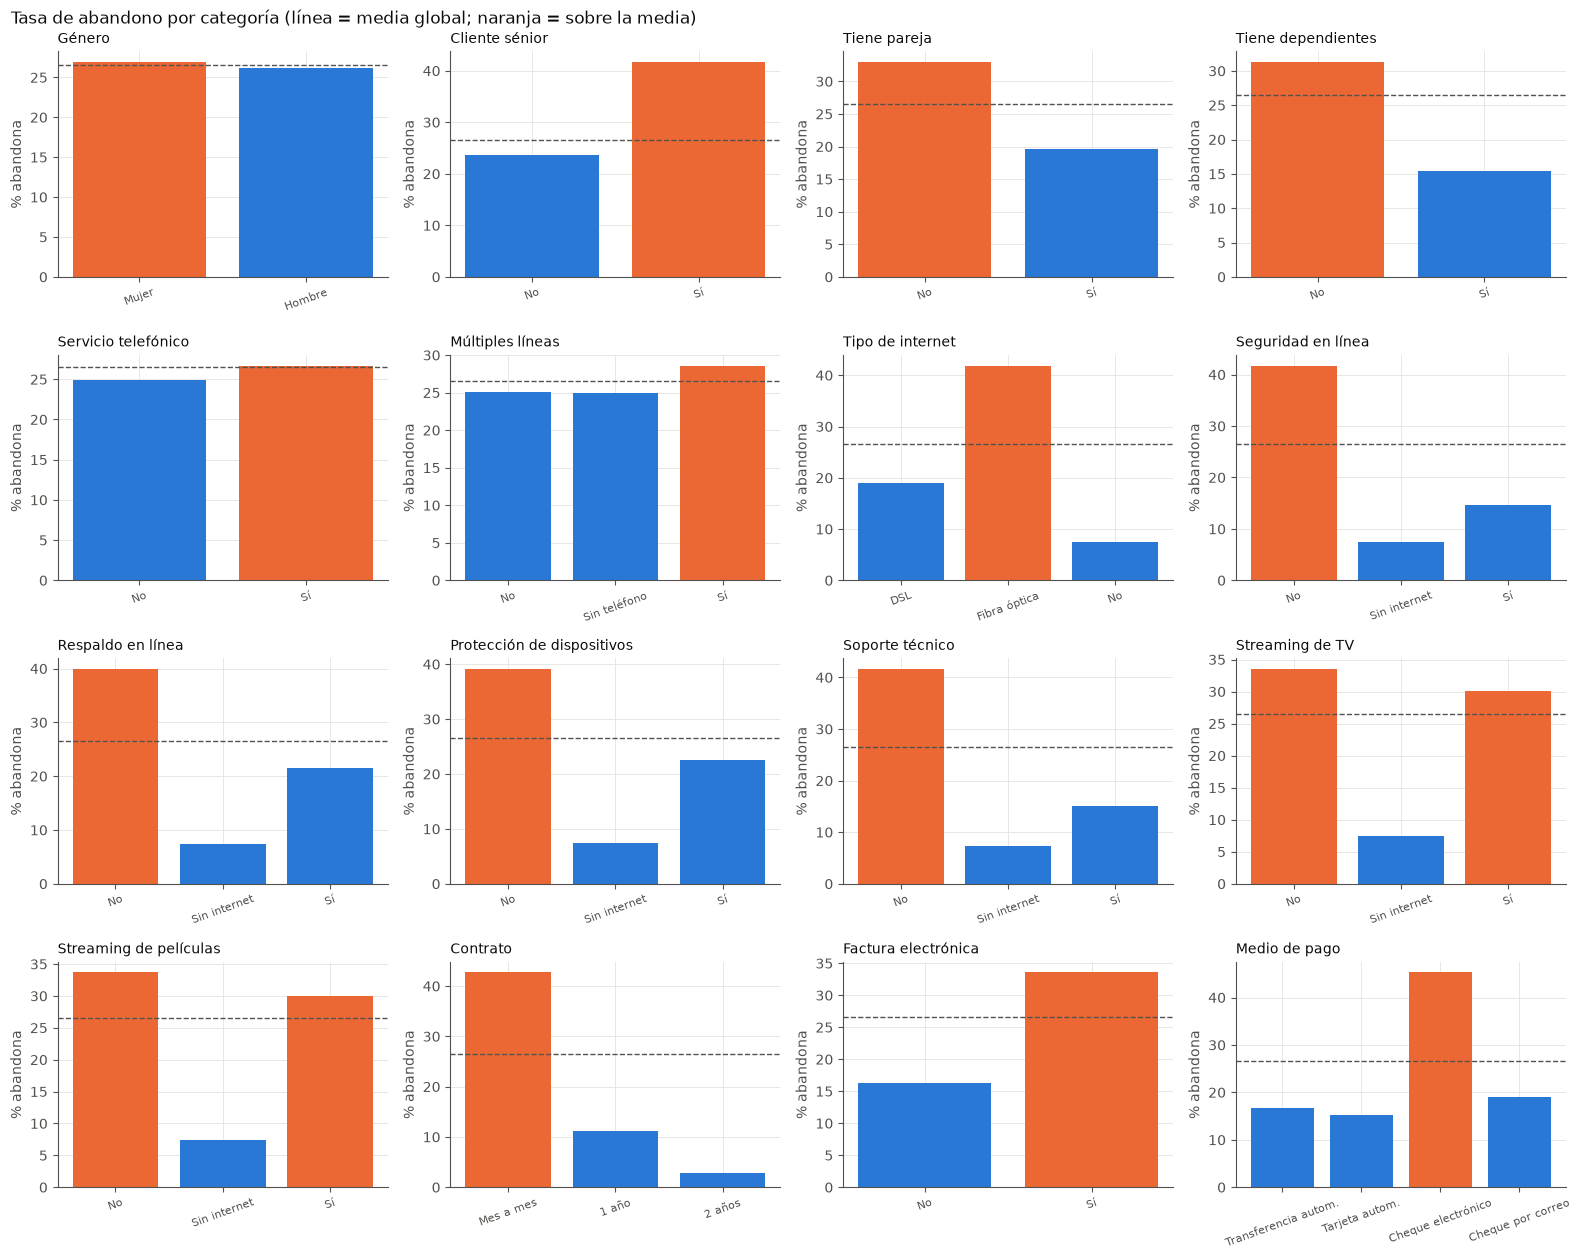

In [9]:
rows = (len(categorical) + 3) // 4
fig, axes = plt.subplots(rows, 4, figsize=(16, 3.2 * rows))
for ax, c in zip(axes.flat, categorical):
    rate = df.groupby(c)[TARGET].agg(churn_rate)
    ax.bar(rate.index.astype(str).map(lambda v: VALUE_LABELS.get(v, v)), rate.values, color=[CHURN if r > base else STAY for r in rate.values])
    ax.axhline(base, color=MUTED, ls="--", lw=1)
    ax.set_title(RAW_LABELS[c], loc="left", fontsize=10)
    ax.set_ylabel("% abandona")
    ax.tick_params(axis="x", labelrotation=20, labelsize=8)
for ax in axes.flat[len(categorical):]:
    ax.remove()
fig.suptitle("Tasa de abandono por categoría (línea = media global; naranja = sobre la media)", x=0.01, ha="left")
fig.tight_layout()
style.save(fig, paths.figure("exploracion", "churn_categoricas.png"))

In [10]:
print("Numéricas por grupo (media / mediana):")
df.groupby(TARGET)[numeric].agg(["mean", "median"]).round(1).T

Numéricas por grupo (media / mediana):


Churn                      No     Yes
tenure         mean      37.6    18.0
               median    38.0    10.0
MonthlyCharges mean      61.3    74.4
               median    64.4    79.6
TotalCharges   mean    2555.3  1531.8
               median  1683.6   703.6

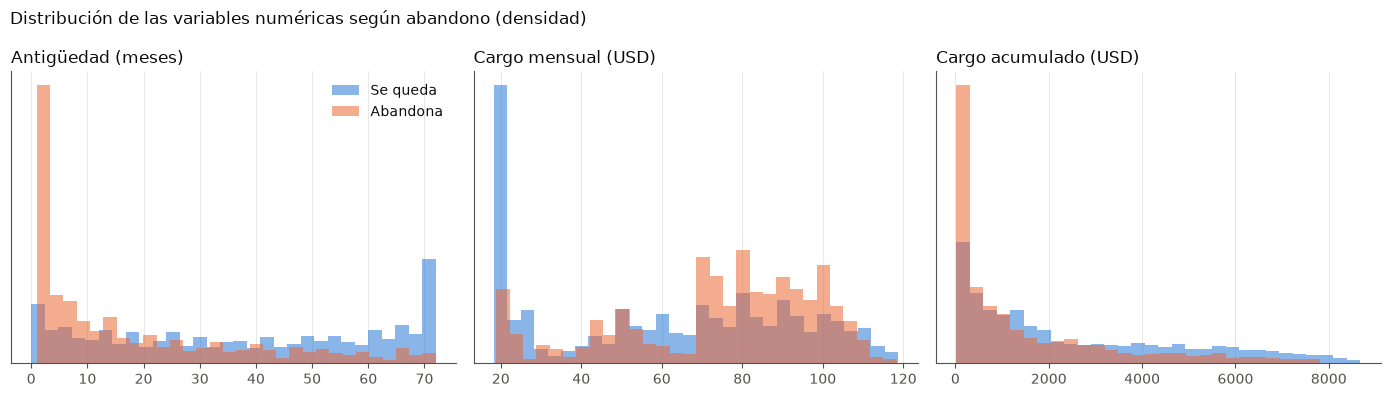

In [11]:
fig, axes = plt.subplots(1, len(numeric), figsize=(14, 4))
for ax, c in zip(axes, numeric):
    for label, color, name in (("No", STAY, "Se queda"), ("Yes", CHURN, "Abandona")):
        ax.hist(df.loc[df[TARGET] == label, c].dropna(), bins=30, density=True, alpha=0.55, color=color, label=name)
    ax.set_title(RAW_LABELS[c], loc="left")
    ax.set_yticks([])
axes[0].legend(frameon=False)
fig.suptitle("Distribución de las variables numéricas según abandono (densidad)", x=0.01, ha="left")
fig.tight_layout()
style.save(fig, paths.figure("exploracion", "churn_numericas.png"))

In [12]:
bins = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
print("Abandono por tramo de antigüedad (meses):")
df.groupby(bins, observed=True)[TARGET].agg(clientes="count", pct_abandona=churn_rate).round(1)

Abandono por tramo de antigüedad (meses):


,clientes,pct_abandona
tenure,,
0-6,1481,52.9
7-12,705,35.9
13-24,1024,28.7
25-48,1594,20.4
49-72,2239,9.5


## 5. Correlación entre numéricas
El cargo acumulado es casi antigüedad × cargo mensual (r = 0,83 con antigüedad): se interpretan juntos.

,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.00,0.25,0.83,-0.35
MonthlyCharges,0.25,1.00,0.65,0.19
TotalCharges,0.83,0.65,1.00,-0.20
Churn,-0.35,0.19,-0.20,1.00


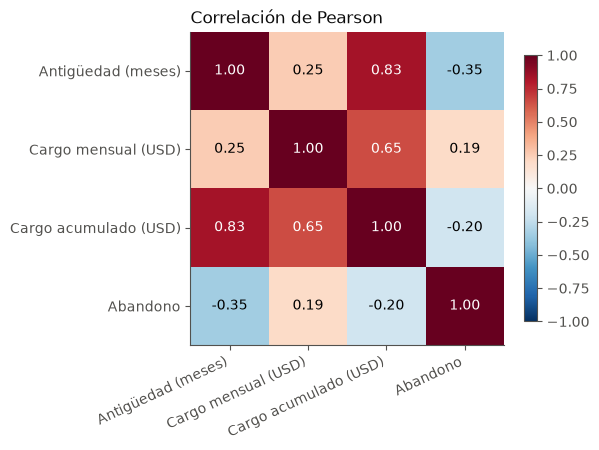

In [13]:
corr = df[numeric].assign(**{TARGET: (df[TARGET] == "Yes").astype(int)}).corr().round(2)
names = [RAW_LABELS[c] for c in corr.columns]
fig, ax = plt.subplots(figsize=(6, 4.8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(corr)), names, rotation=25, ha="right")
ax.set_yticks(range(len(corr)), names)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.iat[i, j]) > 0.6 else "black")
fig.colorbar(im, shrink=0.8)
ax.set_title("Correlación de Pearson", loc="left")
fig.tight_layout()
style.save(fig, paths.figure("exploracion", "churn_correlacion.png"))
corr